# Project 1 - 2026 - Jonathan Gao, Gabriel Lindkvist, Viggo Segersten

# Part 1 - Building a classification pipeline
1. Perform dimension reduction on the data set. Is the data well separated?
2. Train the classifiers using the training data, and perform cross-validation to tune the models that require tuning.
3. Compare the performance of the different classifiers on a test set.

In [ ]:
# Importing and some first checks
import pandas as pd

PATHIM = r"mnist_large//images.csv"
PATHLB = r"mnist_large//labels.csv"

images = pd.read_csv(PATHIM, sep=",", index_col=0)
labels = pd.read_csv(PATHLB, sep=",", index_col=0)

labels = labels.rename(columns={"0":"label"})

print(f"Shape images (before): {images.shape}")
print(f"Shape labels (before): {labels.shape}")

# Compare histograms for pixel intensity betwen classes
df = images.join(labels)
df["mean_intensity"] = images.mean(axis=1)

df.pivot(columns="label", values="mean_intensity").hist(bins=40)

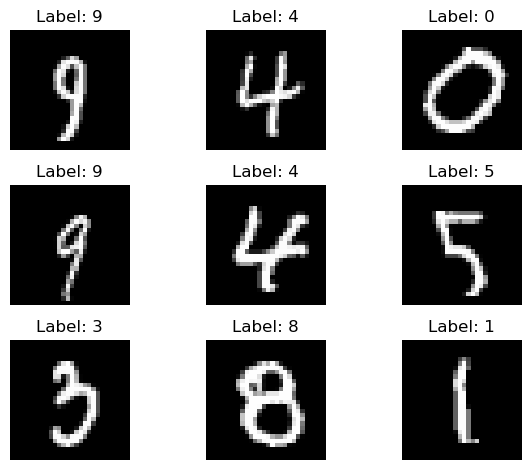

In [ ]:
# Converting to numpy arrays and inspecting further
import matplotlib.pyplot as plt
import numpy as np

images = np.array(images)
labels = np.array(labels).ravel()

n_images = images.shape[0]
n_samples = 9

idx = np.random.choice(n_images, size = n_samples, replace = False)
images_sub = images[idx]
labels_sub = labels[idx]

fig, axes = plt.subplots(3, 3)

for i, ax in enumerate(axes.ravel()):
    img = images_sub[i].reshape(28,28)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {labels_sub[i]}")
    ax.axis("off")

plt.tight_layout()

### Exploring Dimension Reduction via tSNE and UMAP

In [ ]:
# This cell largely contains code from Rebecka's Lecture 4 Demo
# Visualizing tSNE and UMAP projections of the data, then plotting with MATPLOTLIB

np.random.seed(42)

cbPalette = [
    '#000000', '#E69F00', '#56B4E9', '#009E73', '#AAAAAA',
    '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#505050'
]
grayscale = [
    '#000000', '#111111', '#222222', '#333333', '#444444',
    '#555555', '#666666', '#777777', '#888888', '#999999'
]

plt.rcParams.update({
    'figure.figsize': (6, 4),
    'axes.titlesize': 16,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
})


def img2df(img, nrow=28, ncol=None):
    if ncol is None:
        ncol = nrow
    img = np.asarray(img).astype(float).ravel()
    if img.size != nrow * ncol:
        raise ValueError(f'wrong dimensions: {img.size} != {nrow*ncol}')
    x = np.tile(np.arange(1, nrow + 1), ncol)
    y = np.repeat(np.arange(ncol, 0, -1), nrow)
    return pd.DataFrame({'x': x, 'y': y, 'fill': img})


def plot_img(img, label='none', nrow=28, ncol=None, ax=None):
    if ncol is None:
        ncol = nrow
    if ax is None:
        _, ax = plt.subplots(figsize=(2.5, 2.5))
    arr = np.asarray(img).reshape(nrow, ncol)
    cmap = LinearSegmentedColormap.from_list('gray_custom', ['#333333', '#cccccc'])
    ax.imshow(arr, cmap=cmap, origin='upper')
    ax.set_xticks([])
    ax.set_yticks([])
    if label != 'none':
        ax.set_title(f'Label: {label}')
    return ax


def tibble_named(x, names):
    return pd.DataFrame(np.asarray(x), columns=list(names))


def plot_proj(comps, labels, x, y, title='', labelspred=None, ax=None):
    if labelspred is None:
        labelspred = labels
    df = pd.concat([pd.DataFrame({'label': pd.Categorical(labels)}), comps.reset_index(drop=True)], axis=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    colors = pd.Categorical(labelspred).codes
    sc = ax.scatter(df[x], df[y], c=colors, cmap='tab10', s=10, alpha=0.0)
    for xi, yi, lab, ci in zip(df[x], df[y], df['label'].astype(str), colors):
        ax.text(xi, yi, lab, color=plt.cm.tab10(ci % 10), fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    return ax

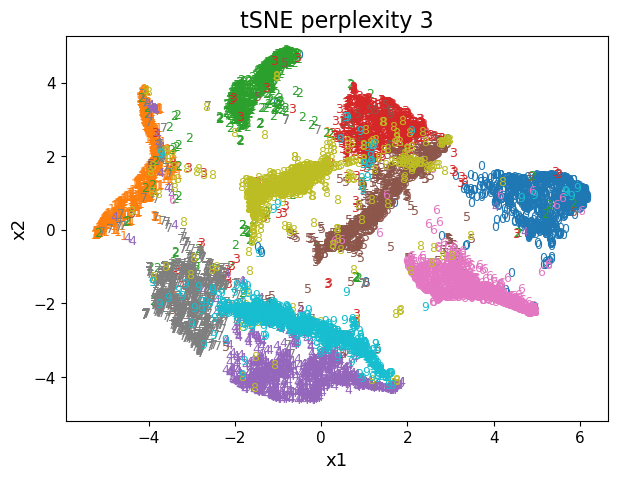

In [ ]:
# Firstly, exploring tSNE projections of the data

from sklearn.manifold import MDS, Isomap, TSNE

nimg = len(labels)
npx = int(np.sqrt(images.shape[1])) # image size in pixels

def center(x):
    x = np.asarray(x)
    return x - x.mean()
# images = images.apply(center, axis=1, result_type='expand')

iz = np.random.choice(np.arange(nimg), 1000, replace=False) # a subset of digits


# tSNE
tsne_N = TSNE(n_components=2, perplexity=3, max_iter=250, random_state=42, init='pca').fit_transform(images)

# final output
plot_proj(tibble_named(tsne_N, ['x1', 'x2']), labels, 'x1', 'x2', 'tSNE perplexity 3')
plt.show()

/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


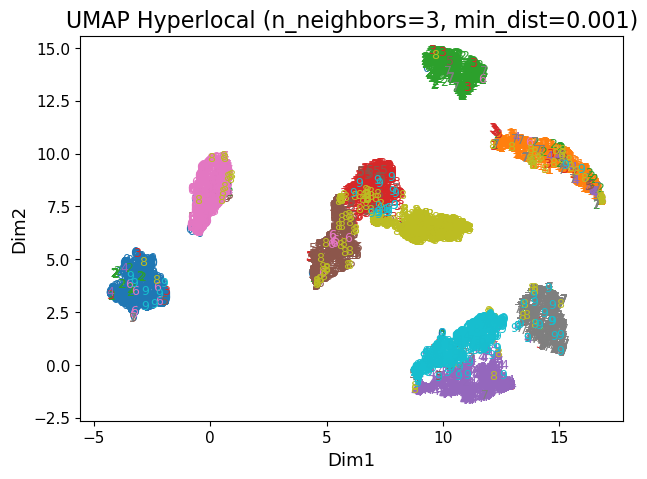

In [ ]:
# Then, exploring UMAP projections of the data

from umap import UMAP

# Fit UMAP
umap_model = UMAP(n_components=2, random_state=42, n_neighbors=5, min_dist=0.01)
umap_embedding = umap_model.fit_transform(images)

# Plot UMAP embedding with true labels
plot_proj(tibble_named(umap_embedding, ['Dim1', 'Dim2']), labels, 'Dim1', 'Dim2', 'UMAP Hyperlocal (n_neighbors=3, min_dist=0.001)')
plt.show()


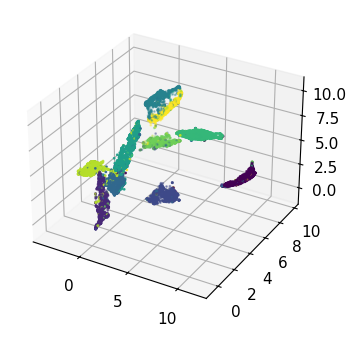

In [ ]:
# Seeing if UMAP n_components=3 gives a better separation of the classes

def draw_umap(n_neighbors=5, min_dist=0.01, n_components=3, metric='euclidean', title=''):
    fit = UMAP(
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        n_components=n_components,
        metric=metric
    )
    u = fit.fit_transform(images);
    fig = plt.figure()
    if n_components == 1:
        ax = fig.add_subplot(111)
        ax.scatter(u[:,0], range(len(u)), c=labels)
    if n_components == 2:
        ax = fig.add_subplot(111)
        ax.scatter(u[:,0], u[:,1], c=labels)
    if n_components == 3:
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(u[:,0], u[:,1], u[:,2], c=labels, s=1)
    plt.title(title, fontsize=18)

draw_umap()

/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


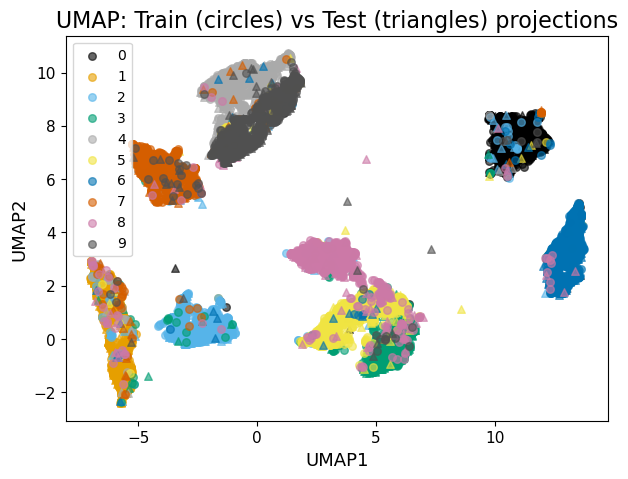

In [ ]:
# Dimension reduction of the training dataset using UMAP with the following parameters:
# n_neighbors=5, min_dist=0.01, n_components=2, random_state=42
# Then, transforming the test dataset using the same UMAP model fitted on the training data, and visualizing the projections

from sklearn.model_selection import train_test_split

# Create a test and train set
X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.25, stratify=labels)

umap_model = UMAP(n_components=2, random_state=42, n_neighbors=5, min_dist=0.01) #Change n_components
umap_train_proj = umap_model.fit_transform(X_train)

umap_test_proj = umap_model.transform(X_test)

# Combine for visualization
umap_train_df = pd.DataFrame(umap_train_proj, columns=['UMAP1', 'UMAP2'])
umap_train_df['set'] = 'Train'
umap_train_df['label'] = y_train.astype(str)

umap_test_df = pd.DataFrame(umap_test_proj, columns=['UMAP1', 'UMAP2'])
umap_test_df['set'] = 'Test'
umap_test_df['label'] = y_test.astype(str)

umap_all = pd.concat([umap_train_df, umap_test_df], ignore_index=True)

# Plot with consistent colors per digit class and markers for train/test
fig, ax = plt.subplots(figsize=(7, 5))
labels_unique = sorted(umap_all['label'].unique())
for i, label in enumerate(labels_unique):
    color = cbPalette[int(label) % len(cbPalette)]

    train_mask = (umap_all['label'] == label) & (umap_all['set'] == 'Train')
    test_mask = (umap_all['label'] == label) & (umap_all['set'] == 'Test')

    if train_mask.any():
        ax.scatter(umap_all.loc[train_mask, 'UMAP1'], umap_all.loc[train_mask, 'UMAP2'],
                  marker='o', s=30, alpha=0.6, color=color, label=f'{label}')
    if test_mask.any():
        ax.scatter(umap_all.loc[test_mask, 'UMAP1'], umap_all.loc[test_mask, 'UMAP2'],
                  marker='^', s=30, alpha=0.6, color=color)

ax.set_title('UMAP: Train (circles) vs Test (triangles) projections')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.legend()
plt.show()

/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


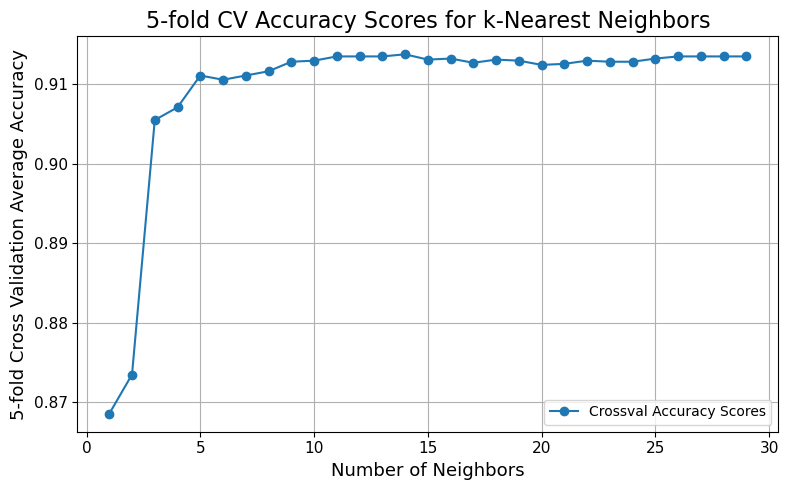

In [ ]:
# Implementing a kNN classifier, using 5-fold CV on the training set to tune  the number of neighbors

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold, cross_val_score

# Rewriting the umap model here to change n_components
umap_model = UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1) #Change n_components
umap_train_proj = umap_model.fit_transform(X_train)

umap_test_proj = umap_model.transform(X_test)


# Implementing a kNN Classifier for different ks from 1 to 30
neighbors = list(range(1, 30))

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

cross_val_accuracy_scores = []

# Looking at the accuracy scores in a 5fold cross validation setting
for k in neighbors:
    reg = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(reg, umap_train_proj, y_train, cv=kfold, scoring="accuracy")
    cross_val_accuracy_scores.append(np.mean(scores))


# Plotting the figure
plt.figure(figsize=(8, 5))
plt.plot(neighbors, cross_val_accuracy_scores, marker='o', label='Crossval Accuracy Scores')
plt.xlabel("Number of Neighbors")
plt.ylabel("5-fold Cross Validation Average Accuracy")
plt.title("5-fold CV Accuracy Scores for k-Nearest Neighbors")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Splitting data and inspecting first 2 PCA components

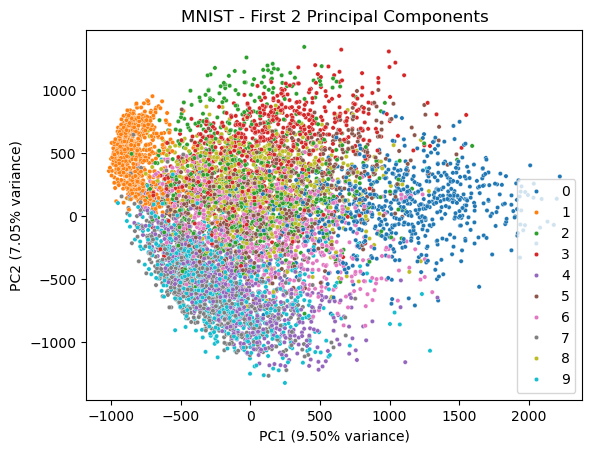

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns


# Fit a temporary PCA just for visualization
pca_vis = PCA(n_components=2)
X_vis = pca_vis.fit_transform(X_train)

# Plot the first two principal components
sns.scatterplot(x=X_vis[:, 0], y=X_vis[:, 1], hue=y_train, palette="tab10", s=10)
plt.title("MNIST - First 2 Principal Components")
plt.xlabel(f"PC1 ({pca_vis.explained_variance_ratio_[0]:.2%} variance)")
plt.ylabel(f"PC2 ({pca_vis.explained_variance_ratio_[1]:.2%} variance)")
plt.show()

### PCA, fitting and CV

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# 1. Build the Logistic Regression Pipeline
log_pipe = Pipeline([
    ('pca', PCA(n_components=87)), # =0.90 to Keep 90% of variance
    ('clf', LogisticRegression(l1_ratio=0, solver='saga', max_iter=500)) # Uses L2 regularization
])

# Define the grid of parameters to test
log_param_grid = {
    'clf__C': [0.1, 1.0, 10.0] # Tune regularization
}

# Run Cross-Validation
log_grid = GridSearchCV(log_pipe, log_param_grid, cv=5, scoring='f1_macro', n_jobs=-1)
log_grid.fit(X_train, y_train)

# -----------------------------------------------------------------------------

# 2. Build the QDA Pipeline
qda_pipe = Pipeline([
    ('pca', PCA(n_components=87)), # =0.90 to Keep 90% of variance
    ('clf', QuadraticDiscriminantAnalysis())
])

qda_param_grid = {
    'clf__reg_param': [0.0001, 0.001, 0.01] # Tune covariance smoothing
}

# Run Cross-Validation
qda_grid = GridSearchCV(qda_pipe, qda_param_grid, cv=5, scoring='f1_macro', n_jobs=-1)
qda_grid.fit(X_train, y_train)

# -----------------------------------------------------------------------------

# 3. Build the KNN Pipeline
knn_pipe = Pipeline([
    ('pca', PCA(n_components=87)), # =0.90 to Keep 90% of variance
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

knn_param_grid = {
    'clf__n_neighbors': [3, 5, 7], # Tune number of neighbors
    'clf__weights': ['uniform', 'distance'] # Tune weighting scheme
}

# Run Cross-Validation
knn_grid = GridSearchCV(knn_pipe, knn_param_grid, cv=5, scoring='f1_macro', n_jobs=-1)
knn_grid.fit(X_train, y_train)

# ------------------------------------------------------------------------------

# 4. Build a Random Forest pipeline
rf_pipe = Pipeline([
    ('pca', PCA(n_components=87)), # =0.90 to Keep 90% of variance
    ('clf', RandomForestClassifier(max_samples=0.5, n_jobs=-1)) # Use 50% of samples for each tree
])

rf_param_grid = {
    'clf__n_estimators': [50, 100, 200], # Tune number of trees
    'clf__max_depth': [5, 10, 20], # Tune maximum depth
    'clf__min_samples_split': [2, 5, 10], # Tune minimum samples to split
    'clf__max_features': ['sqrt', 'log2', 0.5] # Tune maximum features
}

# Run Cross-Validation
rf_grid = GridSearchCV(rf_pipe, rf_param_grid, cv=5, scoring='f1_macro', n_jobs=-1)
rf_grid.fit(X_train, y_train)


# 19.5s

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__max_depth': [5, 10, ...], 'clf__max_features': ['sqrt', 'log2', ...], 'clf__min_samples_split': [2, 5, ...], 'clf__n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computati

### Getting predictions from best models

In [ ]:
# Get predictions from the best model of each type
log_preds = log_grid.predict(X_test)
qda_preds = qda_grid.predict(X_test)
knn_preds = knn_grid.predict(X_test)
rf_preds = rf_grid.predict(X_test)

### Evaluation

--- Logistic Regression Performance ---
Best Parameters: {'clf__C': 1.0}
              precision    recall  f1-score   support

           0       0.92      0.97      0.94       250
           1       0.91      0.95      0.93       250
           2       0.89      0.88      0.89       250
           3       0.88      0.85      0.86       250
           4       0.92      0.91      0.91       250
           5       0.91      0.83      0.87       250
           6       0.90      0.94      0.92       250
           7       0.91      0.93      0.92       250
           8       0.86      0.80      0.83       250
           9       0.88      0.91      0.89       250

    accuracy                           0.90      2500
   macro avg       0.90      0.90      0.90      2500
weighted avg       0.90      0.90      0.90      2500



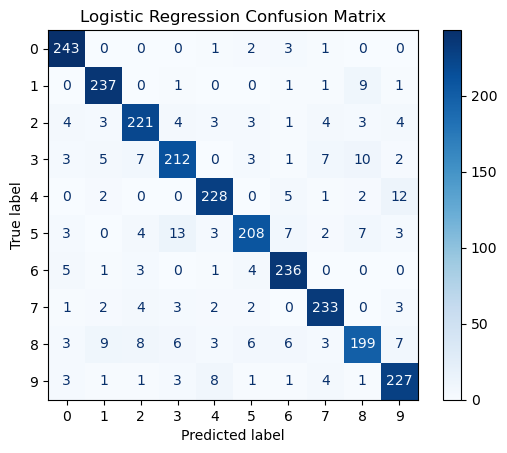

--- QDA Performance ---
Best Parameters: {'clf__reg_param': 0.0001}
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       250
           1       1.00      0.89      0.94       250
           2       0.90      0.97      0.93       250
           3       0.95      0.90      0.92       250
           4       0.97      0.95      0.96       250
           5       0.95      0.92      0.94       250
           6       0.98      0.94      0.96       250
           7       0.96      0.94      0.95       250
           8       0.81      0.97      0.88       250
           9       0.97      0.93      0.95       250

    accuracy                           0.94      2500
   macro avg       0.94      0.94      0.94      2500
weighted avg       0.94      0.94      0.94      2500



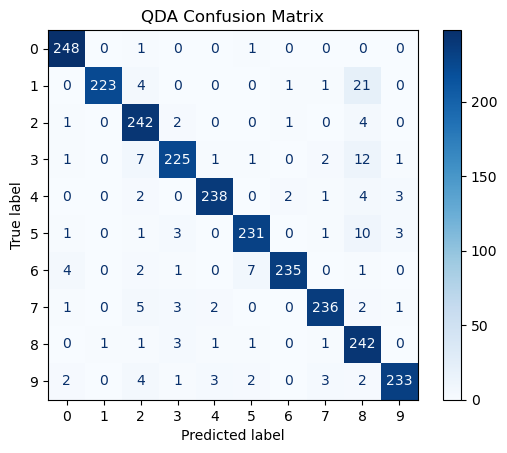

--- KNN Performance ---
Best Parameters: {'clf__n_neighbors': 5, 'clf__weights': 'distance'}
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       250
           1       0.92      0.98      0.95       250
           2       0.97      0.95      0.96       250
           3       0.95      0.94      0.94       250
           4       0.98      0.94      0.96       250
           5       0.94      0.94      0.94       250
           6       0.96      0.98      0.97       250
           7       0.95      0.96      0.95       250
           8       0.97      0.87      0.92       250
           9       0.91      0.97      0.94       250

    accuracy                           0.95      2500
   macro avg       0.95      0.95      0.95      2500
weighted avg       0.95      0.95      0.95      2500



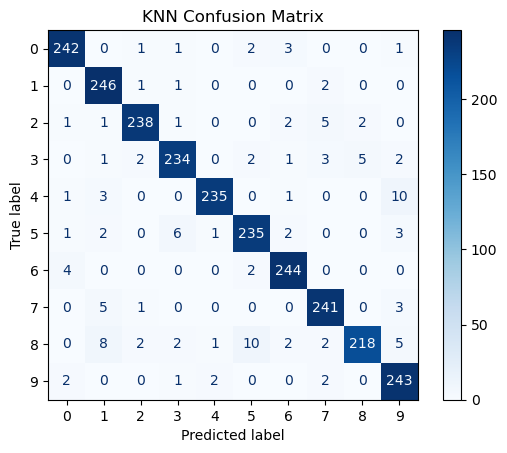

--- Random Forest Performance ---
Best Parameters: {'clf__max_depth': 20, 'clf__max_features': 'log2', 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
              precision    recall  f1-score   support

           0       0.93      0.96      0.94       250
           1       0.95      0.96      0.95       250
           2       0.92      0.90      0.91       250
           3       0.90      0.87      0.89       250
           4       0.88      0.92      0.90       250
           5       0.93      0.88      0.91       250
           6       0.92      0.96      0.94       250
           7       0.95      0.93      0.94       250
           8       0.87      0.88      0.87       250
           9       0.88      0.87      0.88       250

    accuracy                           0.91      2500
   macro avg       0.91      0.91      0.91      2500
weighted avg       0.91      0.91      0.91      2500



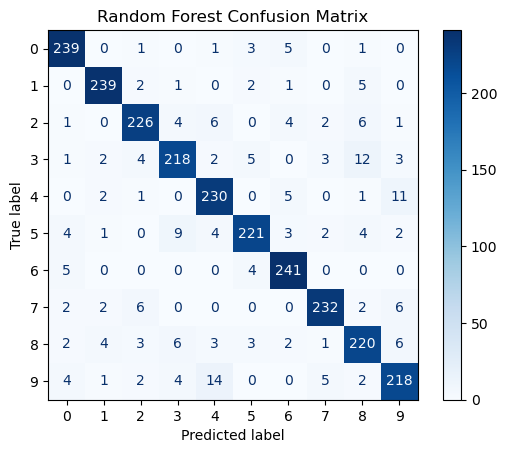

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Evaluating best logistic model
print("--- Logistic Regression Performance ---")
print("Best Parameters:", log_grid.best_params_)
print(classification_report(y_test, log_preds))

# Visualize where Logistic regression is making mistakes
ConfusionMatrixDisplay.from_predictions(y_test, log_preds, cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.show()

#------------------------------------------------------------------------------

# Evaluating best QDA model
print("--- QDA Performance ---")
print("Best Parameters:", qda_grid.best_params_)
print(classification_report(y_test, qda_preds))

# Visualize where QDA is making mistakes
ConfusionMatrixDisplay.from_predictions(y_test, qda_preds, cmap='Blues')
plt.title("QDA Confusion Matrix")
plt.show()

#------------------------------------------------------------------------------

# Evaluating best KNN model
print("--- KNN Performance ---")
print("Best Parameters:", knn_grid.best_params_)
print(classification_report(y_test, knn_preds))

# Visualize where KNN is making mistakes
ConfusionMatrixDisplay.from_predictions(y_test, knn_preds, cmap='Blues')
plt.title("KNN Confusion Matrix")
plt.show()

#------------------------------------------------------------------------------

# Evaluating best Random Forest model
print("--- Random Forest Performance ---")
print("Best Parameters:", rf_grid.best_params_)
print(classification_report(y_test, rf_preds))

# Visualize where Random Forest is making mistakes
ConfusionMatrixDisplay.from_predictions(y_test, rf_preds, cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.show()

#-------------------------------------------------------------------------------

# Checking number of PCs retained in the best models
# best_pipeline_log = log_grid.best_estimator_
# best_pca_step_log = best_pipeline_log.named_steps['pca']
# n_pcs = best_pca_step_log.n_components_
# print(f"The models reached 90% variance using {n_pcs} principal components.")

# best_pipeline_qda = qda_grid.best_estimator_
# best_pca_step_qda = best_pipeline_qda.named_steps['pca']
# n_pcs = best_pca_step_qda.n_components_
# print(f"The QDA model reached 90% variance using {n_pcs} principal components.")

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, ParameterGrid, cross_val_score
import time
import tqdm

### Comparing no dimension reduction, PCA and k-PCA for Random Forest ###

print("Comprehensive Random Forest comparison: raw vs PCA vs kPCA\n")

# Clean numeric issues once for a consistent input matrix
X = x_train.replace([np.inf, -np.inf], np.nan).fillna(0.0)
y = y_train["label"].to_numpy()

# Same RF setup across all evaluations
rf_base = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Keep a compatible model name for later cells in the notebook
rf_model = rf_base

# Stratified CV for classification stability
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # stratified KFold for classification

results = []

# 1) Baseline: no dimensionality reduction
time.sleep(1)  # small pause for readability in output
timer_start = time.time()
scores_raw = cross_val_score(rf_base, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
scores_original = scores_raw
results.append({
    "model": "RF (raw)",
    "params": "-",
    "mean_acc": scores_raw.mean(),
    "std_acc": scores_raw.std()
})
timer_stopped = time.time()
time_original = timer_stopped - timer_start
print(f"Baseline RF (raw) completed in {time_original:.2f} seconds.")


# 2) PCA pipeline: StandardScaler -> PCA -> RF
pca_grid = {
    "pca__n_components": [80, 90, 100, 120]
}

pca_template = Pipeline([
    ("scaler", StandardScaler()), # standardize before PCA
    ("pca", PCA()),
    ("rf", rf_base)
])

scores_pca = []
times_pca = []
for params in tqdm.tqdm(ParameterGrid(pca_grid), desc="Evaluating PCA configurations"):
    timer_start = time.time()
    pca_pipe = pca_template.set_params(**params)
    scores = cross_val_score(pca_pipe, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    scores_pca.append(scores)
    results.append({
        "model": "RF + PCA",
        "params": str(params),
        "mean_acc": scores.mean(),
        "std_acc": scores.std()
    })
    timer_stopped = time.time()
    times_pca.append(timer_stopped - timer_start)
    #print(f"PCA RF with {params['pca__n_components']} components completed in {times_pca[-1]:.2f} seconds.")


# 3) kPCA pipeline: StandardScaler -> KernelPCA -> RF
# Keep grid moderate because kPCA is computationally expensive on MNIST-sized data.
kpca_grid = {
    "kpca__n_components": [80, 100, 120],
    "kpca__gamma": [1e-7, 1e-6, 1e-5],
    "kpca__kernel": ["rbf", "poly"]
}

kpca_template = Pipeline([
    ("scaler", StandardScaler()),
    ("kpca", KernelPCA(fit_inverse_transform=False, eigen_solver="arpack")),
    ("rf", rf_base)
])

scores_kpca = []
times_kpca = []
for params in tqdm.tqdm(ParameterGrid(kpca_grid), desc="Evaluating kPCA configurations"):
    timer_start = time.time()
    kpca_pipe = kpca_template.set_params(**params)
    scores = cross_val_score(kpca_pipe, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    scores_kpca.append(scores)
    timer_stopped = time.time()
    times_kpca.append(timer_stopped - timer_start)
    results.append({
        "model": "RF + kPCA",
        "params": str(params),
        "mean_acc": scores.mean(),
        "std_acc": scores.std()
    })

results_df = pd.DataFrame(results).sort_values("mean_acc", ascending=False).reset_index(drop=True)
results_df["rank"] = np.arange(1, len(results_df) + 1)
results_df = results_df[["rank", "model", "params", "mean_acc", "std_acc"]]

print("\nTop results:")
display(results_df.head(15))

best_row = results_df.iloc[0]
print(
    f"\nBest setup: {best_row['model']} | {best_row['params']} "
    f"-> accuracy {best_row['mean_acc']:.4f} ± {best_row['std_acc']:.4f}"
)


print("\nOriginal data:")
print(f"Cross-validated Accuracy: {scores_original.mean():.4f} ± {scores_original.std():.4f}")

In [ ]:
kpca = KernelPCA(kernel="rbf", n_components=100, degree=3, gamma=1e-3, fit_inverse_transform=True)
pca = PCA(n_components=100)

X_train = X_train.replace([np.inf, -np.inf], np.nan).fillna(0.0)

print("Fitting Kernel PCA...")
X_train_kpca = kpca.fit_transform(X_train)
print(X_train_kpca.shape)

print("Fitting PCA...")
X_train_pca = pca.fit_transform(X_train)
print(X_train_pca.shape)

In [ ]:
### Showing the projection of the training data onto the first  6 principal components (k-PCA)

n_plots = 3  # (PC1,PC2), (PC3,PC4), ..., (PC11,PC12)
n_components_needed = 2 * n_plots

fig, axes = plt.subplots(1, 3, figsize=(10, 6))
axes = axes.ravel()
labels_1d = y_train["label"].to_numpy()

for i in range(n_plots):
    pc_x = 2 * i
    pc_y = 2 * i + 1

    scatter = axes[i].scatter(
        X_train_kpca[:, pc_x],
        X_train_kpca[:, pc_y],
        c=labels_1d,
        cmap="tab10",
        alpha=0.7
    )
    axes[i].set_xlabel(f"Principal Component {pc_x + 1}")
    axes[i].set_ylabel(f"Principal Component {pc_y + 1}")
    #axes[i].set_title(f"PC{pc_x + 1} vs PC{pc_y + 1}")

fig.suptitle("Projection of training data onto the first 6 Kernel PCA components", fontsize=16)
fig.colorbar(scatter, ax=axes.tolist(), label="Digit", orientation="horizontal", shrink=0.8)
plt.show()

In [ ]:
n_plots = 3  # (PC1,PC2), (PC3,PC4), ..., (PC11,PC12)
n_components_needed = 2 * n_plots

fig, axes = plt.subplots(1, 3, figsize=(10, 6))
axes = axes.ravel()
labels_1d = y_train["label"].to_numpy()

for i in range(n_plots):
    pc_x = 2 * i
    pc_y = 2 * i + 1

    scatter = axes[i].scatter(
        X_train_kpca[:, pc_x],
        X_train_kpca[:, pc_y],
        c=labels_1d,
        cmap="tab10",
        alpha=0.7
    )
    axes[i].set_xlabel(f"Principal Component {pc_x + 1}")
    axes[i].set_ylabel(f"Principal Component {pc_y + 1}")
    #axes[i].set_title(f"PC{pc_x + 1} vs PC{pc_y + 1}")

fig.suptitle("Projection of training data onto the first 6 Kernel PCA components", fontsize=16)
fig.colorbar(scatter, ax=axes.tolist(), label="Digit", orientation="horizontal", shrink=0.8)
plt.show()

## Part 2 - Mislabeling

Create a mislabeled data set from the digits data by randomly changing the labels for some of the observations. *Note, you should only create mislabels for your training data - the test data should be clean.*

Redo Part 1 in this setting.

Which methods handle the mislabeling OK? which methods struggle?

You should explore at least 3 levels of mislabeling (some modest, some more severe and some really severe cases), i.e. proportion of mislabeled data. *Please note that your test data should be "clean", i.e. without mislabeling. For each simulation run, make sure you create a clean and separate data set to estimate prediction performance.*

### Defining function to introduce different amounts of mislabeling

In [ ]:
def introduce_label_noise(y, noise_rate=0.20, num_classes=10):
    """
    Randomly replaces a percentage of true labels with random labels.
    """
    # 1. Create a copy to not overwrite the original clean data
    y_noisy = np.copy(y)

    # 2. Calculate how many labels to change
    n_samples = len(y)
    n_noisy = int(noise_rate * n_samples)

    # 3. Randomly select the indices to corrupt (replace=False ensures unique indices)
    noisy_indices = np.random.choice(n_samples, size=n_noisy, replace=False)

    # 4. Generate new random labels (0 to 9 for MNIST)
    # Note: A small fraction of these will randomly land back on their
    # original correct label, which is mathematically expected in symmetric noise.
    random_labels = np.random.randint(0, num_classes, size=n_noisy)

    # 5. Apply the noisy labels
    y_noisy[noisy_indices] = random_labels

    return y_noisy

##### Classifying with mislabeled data

In [ ]:
# Redefining "best" models to save time from grid search

# 1. Build the Logistic Regression Pipeline
log_pipe_best = Pipeline([
    ('pca', PCA(n_components=87)), # This number what earlier shown to retain 90% of variance
    ('clf', LogisticRegression(l1_ratio=0, solver='saga', max_iter=500, C=1.0)) # Uses L2 regularization
])

qda_pipe_best = Pipeline([
    ('pca', PCA(n_components=87)),
    ('clf', QuadraticDiscriminantAnalysis(reg_param=0.001))
])

knn_pipe_best = Pipeline([
    ('pca', PCA(n_components=87)),
    ('clf', KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1))
])

rf_pipe_best = Pipeline([
    ('pca', PCA(n_components=87)), # =0.90 to Keep 90% of variance
    ('clf', RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_split=2,
                                   max_features='log2', max_samples=0.5, n_jobs=-1))
])

#------------------------------------------------------------------------------

# Corrupt 20%, 50% and 80% of training labels
y_train_noise_20 = introduce_label_noise(y_train, noise_rate=0.20)
y_train_noise_50 = introduce_label_noise(y_train, noise_rate=0.50)
y_train_noise_80 = introduce_label_noise(y_train, noise_rate=0.80)


##### Evaluate the performance of the models trained on noisy data

In [ ]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score

# Group base pipelines into a dictionary for easy looping
pipelines = {
    "Logistic Regression": log_pipe_best,
    "QDA": qda_pipe_best,
    "KNN": knn_pipe_best,
    "Random Forest": rf_pipe_best
}

# Group noisy datasets
noise_datasets = {
    "20%": y_train_noise_20,
    "50%": y_train_noise_50,
    "80%": y_train_noise_80
}

# Loop through each model
for model_name, base_pipe in pipelines.items():
    print(f"--- {model_name} Performance ---")

    # Loop through each noise level
    for noise_level, y_noise in noise_datasets.items():

        # 1. Create untrained copy of the pipeline
        current_model = clone(base_pipe)

        # 2. Fit the fresh copy on the current noise level
        current_model.fit(X_train, y_noise)

        # 3. Predict on the clean test set
        preds = current_model.predict(X_test)

        # 4. Calculate and print accuracy
        acc = accuracy_score(y_test, preds)
        print(f"{noise_level} Label Noise: {acc:.4f}")

    print("\n") # Printing blank line between models for readability

--- Logistic Regression Performance ---
20% Label Noise: 0.8716
50% Label Noise: 0.8320
80% Label Noise: 0.6940


--- QDA Performance ---
20% Label Noise: 0.9436
50% Label Noise: 0.9260
80% Label Noise: 0.8324


--- KNN Performance ---
20% Label Noise: 0.9320
50% Label Noise: 0.7592
80% Label Noise: 0.3868


--- Random Forest Performance ---
20% Label Noise: 0.9116
50% Label Noise: 0.8904
80% Label Noise: 0.6764




##### Plotting accuracy for "best" models as proportion of mislabeled data increases

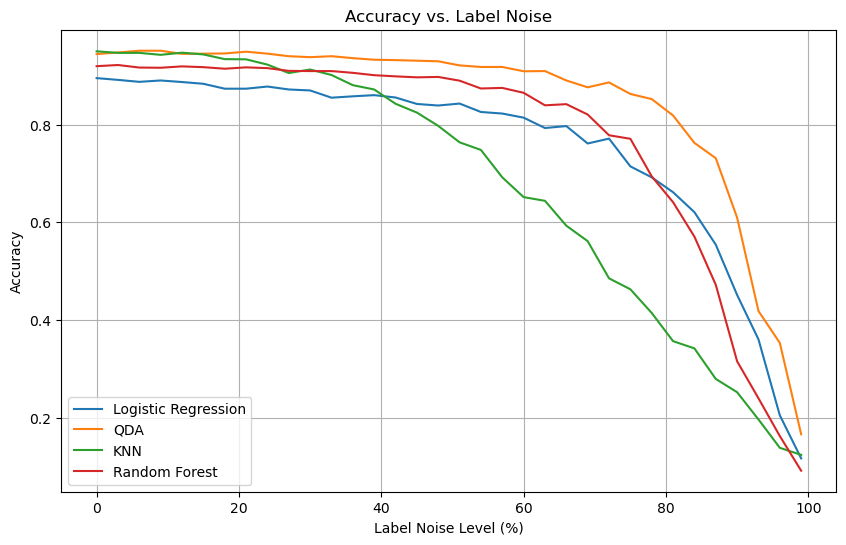

In [ ]:
# Group base pipelines into a dictionary for easy looping
pipelines = {
    "Logistic Regression": log_pipe_best,
    "QDA": qda_pipe_best,
    "KNN": knn_pipe_best,
    "Random Forest": rf_pipe_best
}

noise_levels = np.linspace(0, 99, 34) # From 0% to 99% noise in increments of 3%

fig, ax = plt.subplots(figsize=(10, 6))

# Loop through each model
for model_name, base_pipe in pipelines.items():

    accs = []

    # Loop through each noise level
    for noise_level in noise_levels:

        y_noise = introduce_label_noise(y_train, noise_rate=noise_level/100)

        # 1. Create untrained copy of the pipeline
        current_model = clone(base_pipe)

        # 2. Fit the fresh copy on the current noise level
        current_model.fit(X_train, y_noise)

        # 3. Predict on the clean test set
        preds = current_model.predict(X_test)

        # 4. Calculate and store accuracy
        accs.append(accuracy_score(y_test, preds))

    ax.plot(noise_levels, accs, label=model_name)
plt.title("Accuracy vs. Label Noise")
plt.xlabel("Label Noise Level (%)")
plt.ylabel("Accuracy")
plt.grid()
plt.legend()
plt.show()

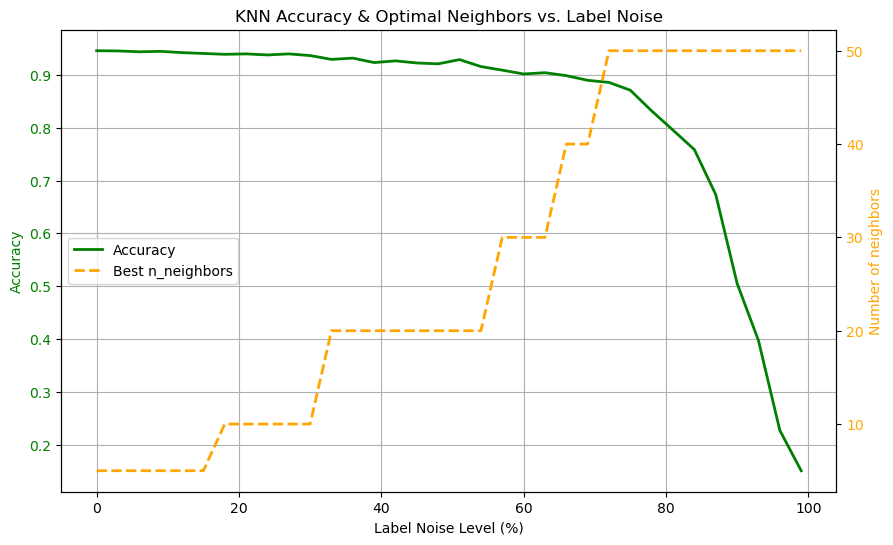

In [ ]:
knn_pipe_test = Pipeline([
    ('pca', PCA(n_components=87)), # =0.90 to Keep 90% of variance
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

knn_test_param_grid = {
    'clf__n_neighbors': [5, 10, 20, 30, 40, 50], # Tune number of neighbors
}

knn_test_grid = GridSearchCV(knn_pipe_test, knn_test_param_grid, cv=5, scoring='f1_macro', n_jobs=-1)

# Group base pipelines into a dictionary for easy looping
pipelines = {
    "KNN": knn_test_grid
}

noise_levels = np.linspace(0, 99, 34) # From 0% to 99% noise in increments of 3%

# Loop through each model
for model_name, base_pipe in pipelines.items():

    accs = []
    n_neighbors_list = []

    # Loop through each noise level
    for noise_level in noise_levels:
        y_noise = introduce_label_noise(y_train, noise_rate=noise_level/100)

        current_model = clone(base_pipe)
        current_model.fit(X_train, y_noise)
        preds = current_model.predict(X_test)

        accs.append(accuracy_score(y_test, preds))
        n_neighbors_list.append(current_model.best_params_["clf__n_neighbors"])

    # ---------------------------------------------------------
    # Plotting with dual axes (to show both accuracy and optimal n_neighbors on the same graph)
    # ---------------------------------------------------------

    # Create the main figure and the first axis (Left)
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Plot Accuracy on ax1
    line1 = ax1.plot(noise_levels, accs, label="Accuracy", color="green", linewidth=2)
    ax1.set_xlabel("Label Noise Level (%)")
    ax1.set_ylabel("Accuracy", color="green")
    ax1.tick_params(axis='y', labelcolor="green")
    ax1.grid(True)

    # Create the second axis (Right) that shares the same X-axis
    ax2 = ax1.twinx()

    # Plot Number of Neighbors on ax2
    line2 = ax2.plot(noise_levels, n_neighbors_list, label="Best n_neighbors", color="orange", linestyle="--", linewidth=2)
    ax2.set_ylabel("Number of neighbors", color="orange")
    ax2.tick_params(axis='y', labelcolor="orange")

    # Combine the legends from both axes into one single legend box
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc="center left")

    plt.title(f"{model_name} Accuracy & Optimal Neighbors vs. Label Noise")
    plt.show()

In [3]:
def mislabel_data(y, mislabel_fraction=0.1, random_state=42, return_indices=False):
    y = np.asarray(y).copy()
    rng = np.random.default_rng(random_state)

    n_samples = len(y)
    n_mislabel = int(mislabel_fraction * n_samples)

    if n_mislabel == 0:
        return (y, np.array([], dtype=int)) if return_indices else y

    mislabel_indices = rng.choice(n_samples, size=n_mislabel, replace=False)
    unique_labels = np.unique(y)

    for idx in mislabel_indices:
        current_label = y[idx]
        y[idx] = rng.choice(unique_labels[unique_labels != current_label])

    return (y, mislabel_indices) if return_indices else y


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

## Investigating mislabeling impact on RF hyperparameters

# Noise levels to evaluate
noise_levels = [0, 20, 40, 50, 60, 80]

# Hyperparameter space for Random Forest tuning
param_grid = {
    "n_estimators": [250, 275, 300, 325, 350],
    "max_depth": [10, 15, 20, 25, 30],
    "min_samples_leaf": [1, 2, 4, 8]
}

# Base model and CV setup
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Collect the best hyperparameters for each noise level
noise_results = []

for noise_level in noise_levels:
    print(f"\nEvaluating noise level: {noise_level}%")

    # Create a noisy version of the labels
    y_train_noisy = mislabel_data(
        y_train.values.ravel(),
        mislabel_fraction=noise_level / 100,
        random_state=123
    )

    # RandomizedSearchCV for this noise level
    randomized_search = RandomizedSearchCV(
        estimator=rf_base,
        param_distributions=param_grid,
        n_iter=30,
        scoring="f1_macro",
        refit=True,
        cv=cv,
        verbose=1,
        n_jobs=-1,
        random_state=123
    )

    randomized_search.fit(x_train, y_train_noisy)

    noise_results.append({
        "noise_level": noise_level,
        "best_n_estimators": randomized_search.best_params_["n_estimators"],
        "best_max_depth": randomized_search.best_params_["max_depth"],
        "best_min_samples_leaf": randomized_search.best_params_["min_samples_leaf"],
        "best_score": randomized_search.best_score_
    })

    print("Best parameters:", randomized_search.best_params_)
    print(f"Best CV F1 score: {randomized_search.best_score_:.4f}")

# Put results in a table for easier inspection
noise_results_df = pd.DataFrame(noise_results)
display(noise_results_df)

# Plot the optimal hyperparameters as a function of noise level
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

axes[0].plot(noise_results_df["noise_level"], noise_results_df["best_score"], marker="o", color="tab:blue")
axes[0].set_ylabel("Cross validation accuracy")
axes[0].set_title("Optimal Random Forest hyperparameters vs. noise level")
axes[0].grid(True, alpha=0.3)

axes[1].plot(noise_results_df["noise_level"], noise_results_df["best_max_depth"], marker="o", color="tab:orange")
axes[1].set_ylabel("max_depth")
axes[1].grid(True, alpha=0.3)

axes[2].plot(noise_results_df["noise_level"], noise_results_df["best_min_samples_leaf"], marker="o", color="tab:green")
axes[2].set_ylabel("min_samples_leaf")
axes[2].set_xlabel("Noise level (%)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

5
